# Muller-Brown Committor Test Case

This notebook compares three committor estimators on the scaled Muller-Brown toy potential: a finite-difference PDE reference, direct endpoint shooting, and local first-exit stitching.

In [1]:
from pathlib import Path
import sys

def find_repo_root(start: Path) -> Path:
    for path in (start, *start.parents):
        if (path / "pyproject.toml").exists() and (path / "trails_md").exists():
            return path
    raise RuntimeError("Could not find Trails-MD repository root")

REPO_ROOT = find_repo_root(Path.cwd().resolve())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

OUTPUT_DIR = REPO_ROOT / "examples" / "toy_committor"

In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np

from examples.toy_committor.muller_brown import MIN_A, MIN_B, basin_predicate, grad, potential
from trails_md.analysis.local_stitch import committor_local_stitch
from trails_md.analysis.pde_reference import solve_pde_committor
from trails_md.analysis.shooting import committor_shoot

## Parameters

The default settings are intentionally moderate for notebook use. Increase `PDE_GRID`, `N_SHOTS_PER_CELL`, `DIRECT_SHOTS`, or `RESOLUTION_SWEEP` for a more expensive validation run.

In [3]:
XLIM = (-1.6, 1.2)
YLIM = (-0.3, 2.1)
RADIUS_A = 0.12
RADIUS_B = 0.12

PDE_GRID = 90
LOCAL_GRID = 18
N_SHOTS_PER_CELL = 40
DIRECT_SHOTS = 60
DT = 2.0e-4
LOCAL_MAX_STEPS = 4000
DIRECT_MAX_STEPS = 20_000
RESOLUTION_SWEEP = [18, 30, 40]

in_a = basin_predicate(MIN_A, RADIUS_A)
in_b = basin_predicate(MIN_B, RADIUS_B)

fractions = np.linspace(0.05, 0.95, 9)
probes = (
    (1.0 - fractions)[:, None] * MIN_A[None, :]
    + fractions[:, None] * MIN_B[None, :]
)

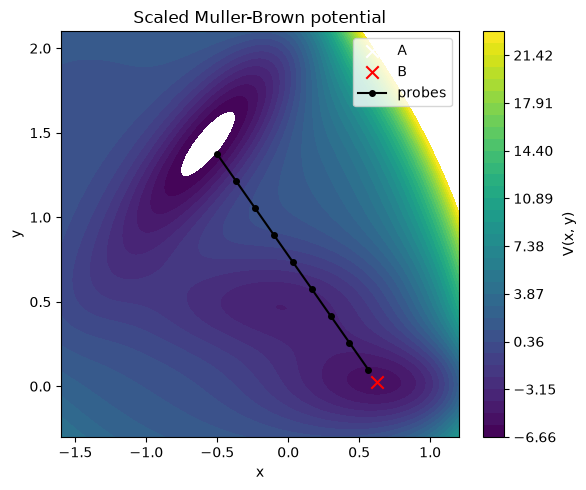

In [4]:
x = np.linspace(*XLIM, 200)
y = np.linspace(*YLIM, 200)
X, Y = np.meshgrid(x, y, indexing="ij")
V = potential(np.stack([X, Y], axis=-1))

fig, ax = plt.subplots(figsize=(6, 5))
levels = np.linspace(np.nanpercentile(V, 1), np.nanpercentile(V, 95), 35)
contour = ax.contourf(x, y, V.T, levels=levels, cmap="viridis")
ax.scatter(*MIN_A, marker="x", color="white", s=80, label="A")
ax.scatter(*MIN_B, marker="x", color="red", s=80, label="B")
ax.plot(probes[:, 0], probes[:, 1], "o-", color="black", ms=4, label="probes")
ax.set_title("Scaled Muller-Brown potential")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend(loc="upper right")
fig.colorbar(contour, ax=ax, label="V(x, y)")
fig.tight_layout()

## PDE Reference

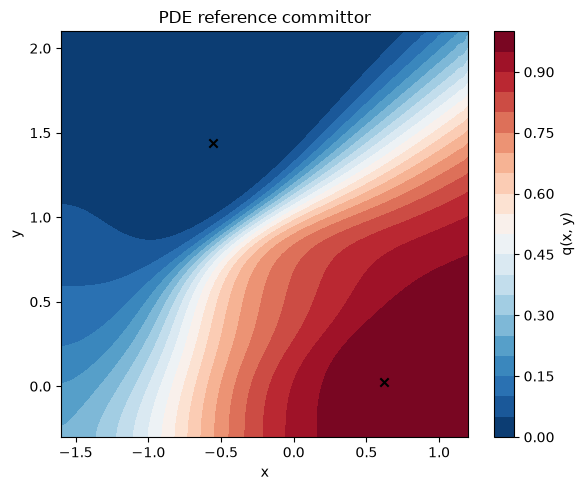

In [5]:
pde = solve_pde_committor(
    grad,
    in_a,
    in_b,
    xlim=XLIM,
    ylim=YLIM,
    nx=PDE_GRID,
    ny=PDE_GRID,
)

fig, ax = plt.subplots(figsize=(6, 5))
image = ax.contourf(
    pde.xs,
    pde.ys,
    pde.q.T,
    levels=np.linspace(0, 1, 21),
    cmap="RdBu_r",
)
ax.scatter(*MIN_A, marker="x", color="black")
ax.scatter(*MIN_B, marker="x", color="black")
ax.set_title("PDE reference committor")
ax.set_xlabel("x")
ax.set_ylabel("y")
fig.colorbar(image, ax=ax, label="q(x, y)")
fig.tight_layout()

## Direct Shooting and Local Stitching

In [6]:
def grid_at(xs: np.ndarray, ys: np.ndarray, values: np.ndarray, point: np.ndarray) -> float:
    i = int(np.argmin(np.abs(xs - point[0])))
    j = int(np.argmin(np.abs(ys - point[1])))
    return float(values[i, j])


def rmse(values: np.ndarray, reference: np.ndarray) -> float:
    return float(np.sqrt(np.nanmean((values - reference) ** 2)))


q_pde_probe = np.array([grid_at(pde.xs, pde.ys, pde.q, point) for point in probes])

shoot = committor_shoot(
    probes,
    grad,
    in_a,
    in_b,
    n_shots=DIRECT_SHOTS,
    seed=2,
    dt=DT,
    max_steps=DIRECT_MAX_STEPS,
)

stitch = committor_local_stitch(
    grad,
    in_a,
    in_b,
    xlim=XLIM,
    ylim=YLIM,
    nx=LOCAL_GRID,
    ny=LOCAL_GRID,
    n_shots_per_cell=N_SHOTS_PER_CELL,
    seed=1,
    dt=DT,
    max_steps=LOCAL_MAX_STEPS,
)

q_stitch_probe = np.array(
    [grid_at(stitch.xs, stitch.ys, stitch.q, point) for point in probes]
)

summary = {
    "rmse_direct_shoot_vs_pde": rmse(shoot.q_mean, q_pde_probe),
    "rmse_local_stitch_vs_pde": rmse(q_stitch_probe, q_pde_probe),
    "local_stitch_isolated_states": int(len(stitch.isolated)),
    "local_stitch_max_abs_residual": float(np.nanmax(np.abs(stitch.residual))),
    "max_markov_total_variation": stitch.markov_check.max_total_variation,
    "max_markov_jensen_shannon": stitch.markov_check.max_jensen_shannon,
    "n_markov_rejected": int(len(stitch.markov_check.rejected_states)),
}
summary

{'rmse_direct_shoot_vs_pde': 0.05790186351523711,
 'rmse_local_stitch_vs_pde': 0.04055555075402942,
 'local_stitch_isolated_states': 0,
 'local_stitch_max_abs_residual': 3.3306690738754696e-16,
 'max_markov_total_variation': 0.4735729386892178,
 'max_markov_jensen_shannon': 0.15642356052908263,
 'n_markov_rejected': 92}

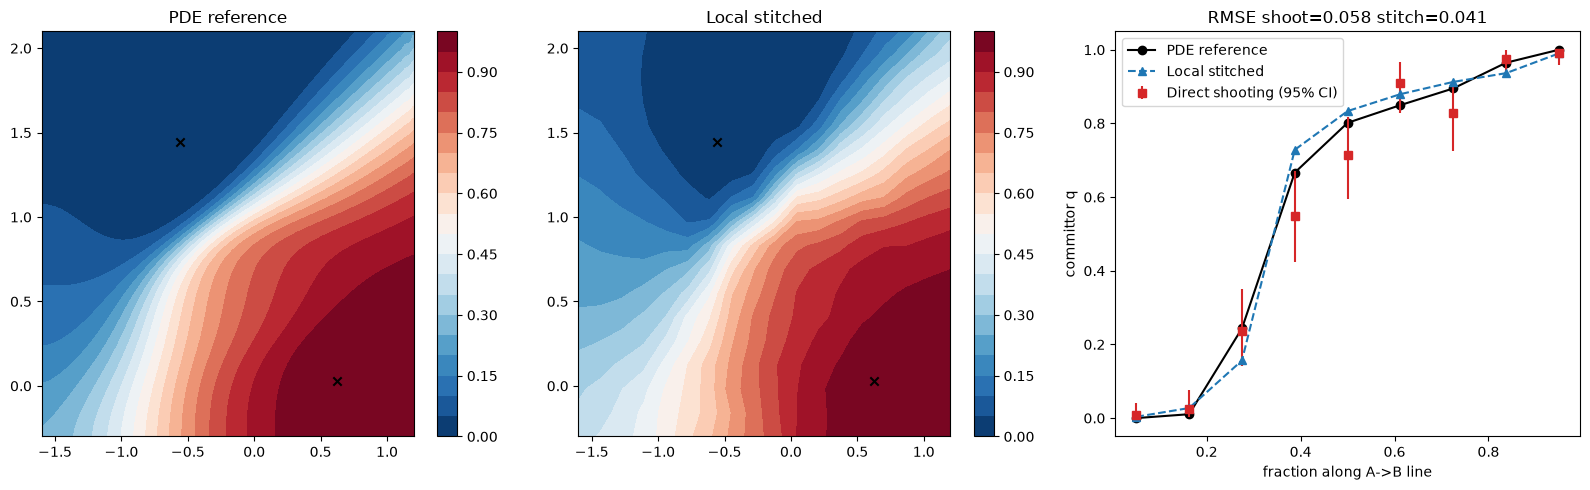

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

im0 = axes[0].contourf(
    pde.xs,
    pde.ys,
    pde.q.T,
    levels=np.linspace(0, 1, 21),
    cmap="RdBu_r",
)
axes[0].scatter(*MIN_A, c="k", marker="x")
axes[0].scatter(*MIN_B, c="k", marker="x")
axes[0].set_title("PDE reference")
fig.colorbar(im0, ax=axes[0])

im1 = axes[1].contourf(
    stitch.xs,
    stitch.ys,
    stitch.q.T,
    levels=np.linspace(0, 1, 21),
    cmap="RdBu_r",
)
axes[1].scatter(*MIN_A, c="k", marker="x")
axes[1].scatter(*MIN_B, c="k", marker="x")
axes[1].set_title("Local stitched")
fig.colorbar(im1, ax=axes[1])

axes[2].plot(fractions, q_pde_probe, "k-o", label="PDE reference")
axes[2].errorbar(
    fractions,
    shoot.q_mean,
    yerr=[shoot.q_mean - shoot.q_lo, shoot.q_hi - shoot.q_mean],
    fmt="s",
    color="tab:red",
    label="Direct shooting (95% CI)",
)
axes[2].plot(fractions, q_stitch_probe, "^--", color="tab:blue", label="Local stitched")
axes[2].set_xlabel("fraction along A->B line")
axes[2].set_ylabel("committor q")
axes[2].legend()
axes[2].set_title(
    f"RMSE shoot={summary['rmse_direct_shoot_vs_pde']:.3f} "
    f"stitch={summary['rmse_local_stitch_vs_pde']:.3f}"
)

fig.tight_layout()

## Resolution Sweep

In [8]:
convergence = []
for grid_size in RESOLUTION_SWEEP:
    max_steps = LOCAL_MAX_STEPS if grid_size == LOCAL_GRID else 2 * LOCAL_MAX_STEPS
    result = committor_local_stitch(
        grad,
        in_a,
        in_b,
        xlim=XLIM,
        ylim=YLIM,
        nx=grid_size,
        ny=grid_size,
        n_shots_per_cell=N_SHOTS_PER_CELL,
        seed=1,
        dt=DT,
        max_steps=max_steps,
    )
    q_probe = np.array([grid_at(result.xs, result.ys, result.q, point) for point in probes])
    convergence.append(
        {
            "grid_size": grid_size,
            "max_steps": max_steps,
            "rmse_local_stitch_vs_pde": rmse(q_probe, q_pde_probe),
            "isolated_states": int(len(result.isolated)),
            "max_abs_residual": float(np.nanmax(np.abs(result.residual))),
            "max_markov_total_variation": result.markov_check.max_total_variation,
            "n_markov_rejected": int(len(result.markov_check.rejected_states)),
        }
    )

convergence

[{'grid_size': 18,
  'max_steps': 4000,
  'rmse_local_stitch_vs_pde': 0.04055555075402942,
  'isolated_states': 0,
  'max_abs_residual': 3.3306690738754696e-16,
  'max_markov_total_variation': 0.4735729386892178,
  'n_markov_rejected': 92},
 {'grid_size': 30,
  'max_steps': 8000,
  'rmse_local_stitch_vs_pde': 0.049228427541893056,
  'isolated_states': 0,
  'max_abs_residual': 3.3306690738754696e-16,
  'max_markov_total_variation': 0.5531914893617021,
  'n_markov_rejected': 331},
 {'grid_size': 40,
  'max_steps': 8000,
  'rmse_local_stitch_vs_pde': 0.030436624513393472,
  'isolated_states': 0,
  'max_abs_residual': 5.551115123125783e-16,
  'max_markov_total_variation': 0.6709549727857497,
  'n_markov_rejected': 773}]

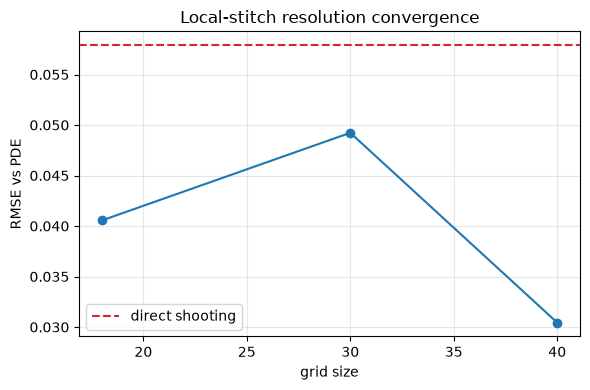

In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(
    [entry["grid_size"] for entry in convergence],
    [entry["rmse_local_stitch_vs_pde"] for entry in convergence],
    "o-",
    color="tab:blue",
)
ax.axhline(summary["rmse_direct_shoot_vs_pde"], color="tab:red", ls="--", label="direct shooting")
ax.set_xlabel("grid size")
ax.set_ylabel("RMSE vs PDE")
ax.set_title("Local-stitch resolution convergence")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()

In [10]:
report = {
    "probe_fraction_along_AB": fractions.tolist(),
    "q_pde": q_pde_probe.tolist(),
    "q_direct_shoot_mean": shoot.q_mean.tolist(),
    "q_direct_shoot_95CI": list(zip(shoot.q_lo.tolist(), shoot.q_hi.tolist())),
    "q_local_stitch": q_stitch_probe.tolist(),
    **summary,
    "resolution_convergence": convergence,
}

output_path = OUTPUT_DIR / "notebook_validation_report.json"
output_path.write_text(json.dumps(report, indent=2), encoding="utf-8")
output_path

PosixPath('/home/dm/Dibyendu/GitHub/Trails-MD/examples/toy_committor/notebook_validation_report.json')